# Credit Risk - Credit score Analysis Using linear regression 

Primary goal: predict the applicant's CIBIL credit score from application-time features using Linear regression

## Setup & Data Loading

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, LogisticRegression
from sklearn.dummy import DummyRegressor
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score, roc_auc_score, accuracy_score)

In [2]:
df = pd.read_csv(r'D:\Machine Learning Models\credit_risk.csv', encoding='utf-8')
print(df.shape)
df.head()

(25000, 22)


,applicant_id,age,gender,marital_status,city_tier,state,employment_type,bank_account_vintage_years,monthly_income_inr,existing_loans_count,...,num_credit_inquiries_last_6m,late_payments_last_12m,loan_amount_requested_inr,loan_tenure_months,loan_purpose,collateral_provided,cibil_score,interest_rate_offered_pct,default_risk_score,default_flag
0,APP106868,22,Male,Single,Tier 3,Haryana,Salaried - PSU,0.5,12000,1,...,2.0,0,149000,48,Personal Expense,No,649,24.84,1.67,0
1,APP124016,35,Female,Divorced,Tier 2,Gujarat,Salaried - Private,0.5,32500,3,...,0.0,1,156000,60,Personal Expense,No,538,25.25,4.47,0
2,APP109668,41,Male,Married,Tier 2,Uttar Pradesh,Salaried - Government,2.8,52500,0,...,0.0,0,70000,36,Wedding,No,636,20.46,0.19,0
3,APP113640,29,Female,Married,Tier 2,Kerala,Salaried - PSU,0.7,15500,1,...,0.0,1,108000,48,Education,No,721,15.27,0.26,0
4,APP114018,31,Male,Married,Tier 1,Punjab,Self-Employed Professional,4.7,269600,2,...,0.0,2,466000,24,Education,No,586,25.52,2.10,0


## 2. Data quality
**findings**

In [3]:
df.isna().sum()

applicant_id                      0
age                               0
gender                            0
marital_status                    0
city_tier                         0
state                             0
employment_type                   0
bank_account_vintage_years      375
monthly_income_inr                0
existing_loans_count              0
existing_emi_monthly_inr        500
credit_utilization_ratio_pct      0
num_credit_inquiries_last_6m    250
late_payments_last_12m            0
loan_amount_requested_inr         0
loan_tenure_months                0
loan_purpose                      0
collateral_provided               0
cibil_score                       0
interest_rate_offered_pct         0
default_risk_score                0
default_flag                      0
dtype: int64

In [4]:
print("missing per column:")
print(df.isna().sum()[df.isna().sum() > 0])
print("\ndefault_flag rate:", round(df['default_flag'].mean(), 4))
df.describe().T.round(1)

missing per column:
bank_account_vintage_years      375
existing_emi_monthly_inr        500
num_credit_inquiries_last_6m    250
dtype: int64

default_flag rate: 0.0614


,count,mean,std,min,25%,50%,75%,max
age,25000.0,35.3,8.6,21.0,29.0,35.0,41.0,65.0
bank_account_vintage_years,24625.0,4.0,3.9,0.5,1.1,2.8,5.5,25.0
monthly_income_inr,25000.0,54832.4,38347.5,12000.0,29500.0,45100.0,68700.0,727000.0
existing_loans_count,25000.0,1.1,1.1,0.0,0.0,1.0,2.0,6.0
existing_emi_monthly_inr,24500.0,11705.6,10297.4,0.0,5100.0,9000.0,15100.0,202300.0
credit_utilization_ratio_pct,25000.0,41.6,19.8,0.0,27.8,41.3,55.0,100.0
num_credit_inquiries_last_6m,24750.0,1.3,1.1,0.0,0.0,1.0,2.0,9.0
late_payments_last_12m,25000.0,1.4,1.3,0.0,0.0,1.0,2.0,8.0
loan_amount_requested_inr,25000.0,158457.2,104231.5,25000.0,88000.0,133000.0,199000.0,1519000.0
loan_tenure_months,25000.0,42.4,19.2,12.0,24.0,36.0,60.0,84.0


## EDA

four key views:
1. CIBIL distribution - roughly normal, centered 
2. CIBIL vs credit utilization - clear negative trend, the strongest single driver.
3. Mean CIBIL by late payments - monotonic decline 
4. Numeric correlation matrix - reveals both the signal and the leakage trap

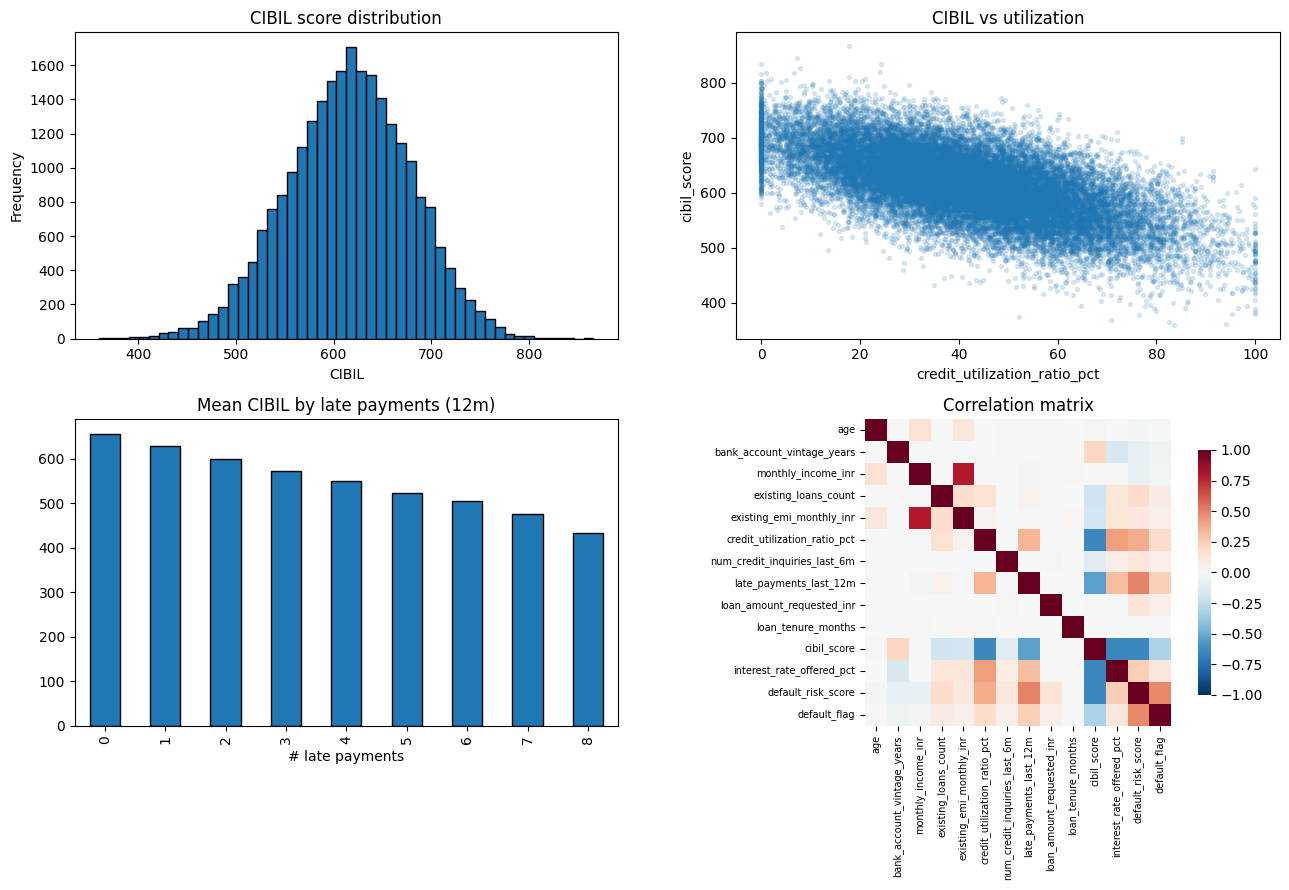

Correlation with cibil_score:
interest_rate_offered_pct      -0.656
default_risk_score             -0.643
credit_utilization_ratio_pct   -0.641
late_payments_last_12m         -0.543
default_flag                   -0.310
existing_loans_count           -0.199
existing_emi_monthly_inr       -0.181
num_credit_inquiries_last_6m   -0.113
monthly_income_inr              0.000
loan_tenure_months              0.001
loan_amount_requested_inr       0.006
age                             0.009
bank_account_vintage_years      0.207
Name: cibil_score, dtype: float64


In [11]:
num_cols = ['age', 'bank_account_vintage_years', 'monthly_income_inr', 'existing_loans_count',
            'existing_emi_monthly_inr', 'credit_utilization_ratio_pct', 'num_credit_inquiries_last_6m',
            'late_payments_last_12m', 'loan_amount_requested_inr', 'loan_tenure_months', 'cibil_score',
            'interest_rate_offered_pct', 'default_risk_score', 'default_flag']

corr = df[num_cols].corr()

fig, axes = plt.subplots(2, 2, figsize=(13, 9))

# histogram of cibil_score
df['cibil_score'].plot.hist(
    bins=50, edgecolor='k', ax=axes[0, 0],
    title='CIBIL score distribution', xlabel='CIBIL'
    )

# Scatter
df.plot.scatter(
    x='credit_utilization_ratio_pct', y='cibil_score',
    alpha=0.15, s=8, ax=axes[0, 1],
    title='CIBIL vs utilization'
)    

# Bar of mean CIBIL by late payments
df.groupby('late_payments_last_12m')['cibil_score'].mean().plot.bar(
    edgecolor='k', ax=axes[1, 0],
    title='Mean CIBIL by late payments (12m)', xlabel='# late payments'
)

# correlation heatmap
sns.heatmap(
    corr, cmap='RdBu_r', vmin=-1, vmax=1,
    square=True, cbar_kws={'shrink': 0.8}, ax=axes[1, 1]
)
axes[1, 1].set_title('Correlation matrix')
axes[1, 1].tick_params(axis='x', rotation=90, labelsize=7)
axes[1, 1].tick_params(axis='y', labelsize=7)

plt.tight_layout()
plt.show()

print("Correlation with cibil_score:")
print(corr['cibil_score'].drop('cibil_score').sort_values().round(3))